In [1]:
# Shim: notebook tidak punya __file__.
import os
__file__ = os.path.abspath("keras_regresi.ipynb")

# # Praktikum 3 — Regresi dengan Keras
#
# (a) Regresi dummy `luas -> harga` (Dense 10 relu, output 1, loss mse, 100 epoch) + tugas ubah learning rate.
# (b) MLP regresi pada data Boston (Dense 64 relu -> 32 relu -> 1, Adam 1e-3, 200 epoch), plot loss/MAE + RMSE.
#
# Seed dipatok: `random_state=42`, `tf.keras.utils.set_random_seed(42)`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from sklearn.datasets import fetch_openml
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

HERE = Path(__file__).resolve().parent
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)
SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
print("tf", tf.__version__)

tf 2.15.1


# ## (a) Regresi dummy: luas -> harga

In [3]:
data = pd.DataFrame({'luas': [50, 60, 70, 80, 90],
                     'harga': [500, 600, 700, 800, 900]})
X = data[['luas']]
y = data[['harga']]

sx = StandardScaler(); sy = StandardScaler()
Xs = sx.fit_transform(X); ys = sy.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(Xs, ys, test_size=0.2, random_state=SEED)

# ### Tugas 4 — ubah learning rate, bandingkan loss
#
# 4 sampel latih -> full-batch tiap step, 100 epoch. Learning rate diuji 4 orde besaran.

loss akhir (lr=1e-3): 0.600235
Prediksi (skala ternormalisasi): [-0.0161]
Prediksi harga asli            : [697.7]
Aktual harga asli              : [600.]



Tugas 4 - pengaruh learning rate:
 learning_rate  loss_awal  loss_akhir  loss_min
      0.000100   1.066133    0.988751  0.988751
      0.001000   1.066133    0.600235  0.600235
      0.010000   1.066133    0.001676  0.001676
      0.100000   1.066133    0.000010  0.000003
      1.000000   1.066133    0.250079  0.250079


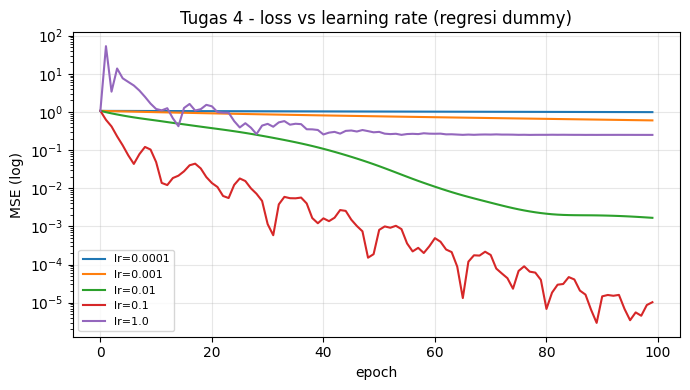

In [4]:
def regresi_dummy(lr=1e-3, epochs=100):
    tf.keras.utils.set_random_seed(SEED)
    m = tf.keras.Sequential([tf.keras.Input(shape=(1,)),
                             tf.keras.layers.Dense(10, activation='relu'),
                             tf.keras.layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    hist = m.fit(X_train, y_train, epochs=epochs, verbose=0)
    pred_s = m.predict(X_test, verbose=0)
    return m, hist, pred_s


model_a, hist_a, pred_a = regresi_dummy()
print("loss akhir (lr=1e-3):", f"{hist_a.history['loss'][-1]:.6f}")
print("Prediksi (skala ternormalisasi):", np.round(pred_a.ravel(), 4))
print("Prediksi harga asli            :", np.round(sy.inverse_transform(pred_a).ravel(), 1))
print("Aktual harga asli              :", sy.inverse_transform(y_test).ravel())

baris = []
for lr in (1e-4, 1e-3, 1e-2, 1e-1, 1.0):
    m, hist, _ = regresi_dummy(lr=lr)
    baris.append(dict(learning_rate=lr, loss_awal=hist.history['loss'][0],
                      loss_akhir=hist.history['loss'][-1],
                      loss_min=min(hist.history['loss'])))
df_lr = pd.DataFrame(baris)
print("\nTugas 4 - pengaruh learning rate:")
print(df_lr.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
df_lr.to_csv(OUT / "hasil_learning_rate_dummy.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for lr in (1e-4, 1e-3, 1e-2, 1e-1, 1.0):
    _, hist, _ = regresi_dummy(lr=lr)
    ax.plot(hist.history['loss'], label=f"lr={lr}")
ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('MSE (log)')
ax.set_title('Tugas 4 - loss vs learning rate (regresi dummy)')
ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "01_loss_vs_learning_rate.png", dpi=120)

# ## (b) MLP regresi pada data Boston
#
# **Deviasi dari modul:** `sklearn.datasets.load_boston` dihapus sejak scikit-learn 1.2.
# Pengganti resmi: `fetch_openml(name='boston', version=1, as_frame=True)` (butuh internet
# sekali untuk cache). Bila jaringan gagal, fallback ke `fetch_california_housing`
# (dicatat di README).

Boston Housing (OpenML id 531, 506 sampel x 13 fitur) | X: (506, 13)


RMSE validasi: 3.2354 (ribu USD) | MAE: 2.0946
MSE latih akhir: 4.9326 | MSE validasi akhir: 10.4680
MAE latih akhir: 1.6304 | MAE validasi akhir: 2.0946


RMSE disimpan di output/riwayat_boston.csv + 3 gambar.


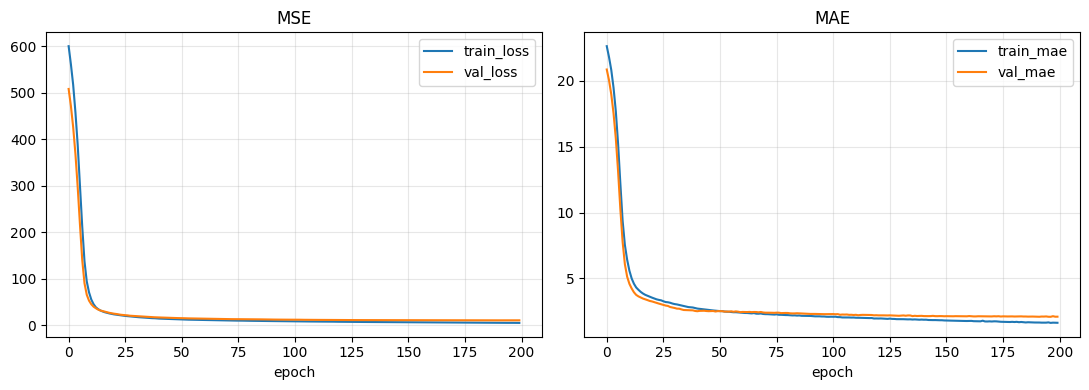

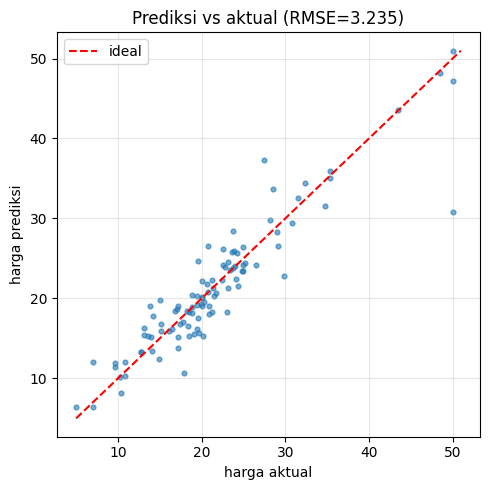

In [5]:
try:
    ds = fetch_openml(name='boston', version=1, as_frame=True)
    Xb = ds.data.astype(float).values
    yb = ds.target.astype(float).values
    nama_data = "Boston Housing (OpenML id 531, 506 sampel x 13 fitur)"
except Exception as e:      # fallback bila OpenML tidak dapat diakses
    from sklearn.datasets import fetch_california_housing
    ds = fetch_california_housing(as_frame=True)
    Xb, yb = ds.data.values, ds.target.values
    nama_data = f"California Housing (padanan Boston, sebab: {type(e).__name__})"
print(nama_data, "| X:", Xb.shape)

scaler = StandardScaler()
Xs = scaler.fit_transform(Xb)
X_train, X_val, y_train, y_val = train_test_split(Xs, yb, test_size=0.2, random_state=SEED)

tf.keras.utils.set_random_seed(SEED)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=200, batch_size=32, verbose=0)

pred = model.predict(X_val, verbose=0).ravel()
rmse = float(np.sqrt(mean_squared_error(y_val, pred)))
mae = float(mean_absolute_error(y_val, pred))
print(f"RMSE validasi: {rmse:.4f} (ribu USD) | MAE: {mae:.4f}")
print(f"MSE latih akhir: {h.history['loss'][-1]:.4f} | MSE validasi akhir: {h.history['val_loss'][-1]:.4f}")
print(f"MAE latih akhir: {h.history['mae'][-1]:.4f} | MAE validasi akhir: {h.history['val_mae'][-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.history['loss'], label='train_loss')
ax[0].plot(h.history['val_loss'], label='val_loss')
ax[0].set_title('MSE'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h.history['mae'], label='train_mae')
ax[1].plot(h.history['val_mae'], label='val_mae')
ax[1].set_title('MAE'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "02_kurva_boston.png", dpi=120)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_val, pred, s=12, alpha=.6)
lim = [min(y_val.min(), pred.min()), max(y_val.max(), pred.max())]
ax.plot(lim, lim, 'r--', label='ideal')
ax.set_xlabel('harga aktual'); ax.set_ylabel('harga prediksi')
ax.set_title(f'Prediksi vs aktual (RMSE={rmse:.3f})'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "03_prediksi_vs_aktual.png", dpi=120)

pd.DataFrame({'epoch': np.arange(1, 201),
              'loss': h.history['loss'], 'val_loss': h.history['val_loss'],
              'mae': h.history['mae'], 'val_mae': h.history['val_mae']}
             ).to_csv(OUT / "riwayat_boston.csv", index=False)
print("RMSE disimpan di output/riwayat_boston.csv + 3 gambar.")